# ITER 3D: vertical displacement with halo currents and voltage-driven coils

This notebook follows `examples/ITER_3D_evol_coils_edge`: the vertical displacement event of the 2D tutorial, now with the
field solved on a **3D** model of the machine and three new physical effects:

* **3D solid conductors**: the vessel and the passive structures are `SOLID_CONDUCTOR` cells of the 3D nodal A-V
  formulation (`AV3D_edge`, edge elements for $A$, nodal $V$), with the electric potential $V$ (charge conservation). Besides the toroidal eddy
  currents they can carry **poloidal** currents, which the 2D model cannot represent. Here the vector potential uses
  **edge** (Nedelec) elements (`AV3D_edge`): its DOFs are circulations along the mesh edges, and a tree-cotree gauge
  fixes it;
* **halo currents**: when the plasma is limited, a thin layer of open field lines outside the last closed flux
  surface (the halo) carries part of the plasma current; its poloidal current flows *into the wall* and back,
  closing through the vessel. The algorithm injects it as nodal currents (`AMPS`) on the wall nodes;
* **voltage-driven coils**: the central solenoid modules and the PF coils are `STRANDED_COIL` cells with their circuit
  equation $V = R\,i + d\Phi/dt$, fed by constant voltages: their currents react to the plasma motion, instead of
  being frozen as in the 2D tutorial.

**How the 3D model is coupled with the plasma.** The plasma stays axisymmetric and lives on the 2D vacuum-chamber
mesh of the equilibrium. The field is solved on a thin toroidal **sector** of 2 degrees (four cells along the torus,
cyclic symmetry between its faces) obtained by revolving the 2D mesh. At every Picard iteration the 2D plasma current
density (toroidal and poloidal) and the halo currents are *projected* onto every toroidal station of the sector; after
the solve, the toroidal vector potential is *averaged* over the stations to give the flux $\psi$ seen by the plasma.

The run takes about 40 minutes (the equilibrium, then 22 steps of 30 ms, each a Picard iteration of 3D solves on a
quadratic mesh of 464 000 nodes).
Read the 2D tutorials first; theory: *Theory - Plasma equilibrium and evolution* (3D coupling, halo currents),
*Circuits* (stranded coils).

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../examples/ITER_3D_evol_coils_edge").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_ITER_3D_evol_coils_edge_"))
for name in ("ITER_3D_evol_coils_edge.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

import json, subprocess, sys, time, vtk
from pytec3d import Algorithm, element_library
from pytec3d.coordinate_system import YAxisCylindricalCoordinateSystem, SphericalCoordinateSystem

from matplotlib.collections import PolyCollection
from matplotlib.tri import Triangulation

def polygons(grid, mask=None):
    """The (R, Z) polygons of the cells of a 2D grid (all of them, or those where mask is True)."""
    g = pv.wrap(grid)
    points, conn, offset = g.points[:, :2], g.cell_connectivity, g.cell_offsets
    ids = np.arange(g.n_cells) if mask is None else np.flatnonzero(mask)
    return [points[conn[offset[i]:offset[i + 1]]] for i in ids]

def fill(ax, grid, mask, values=None, **kwargs):
    """Draw cells: one colour (facecolor=...) or coloured by the cell values (cmap=..., clim=...)."""
    collection = PolyCollection(polygons(grid, mask), **kwargs)
    if values is not None:
        collection.set_array(np.asarray(values)[mask])
    ax.add_collection(collection)
    return collection

def triangulation(grid):
    """The grid as matplotlib triangles over its points (for contours of point arrays such as PSI)."""
    t = pv.wrap(grid).triangulate()
    return Triangulation(t.points[:, 0], t.points[:, 1], t.cells.reshape(-1, 4)[:, 1:])

def frame(ax, r=(0.0, 13.0), z=(-9.0, 9.0)):
    ax.set_xlim(*r); ax.set_ylim(*z); ax.set_aspect("equal"); ax.set_xlabel("R [m]"); ax.set_ylabel("Z [m]")

working in a temporary folder: pytec3d_ITER_3D_evol_coils_edge_0p29mzj3


## The initial equilibrium

As in the 2D evolution, we run the equilibrium macro `examples/ITER_2D_carma/macro.py` (the quadratic mesh) in a sub-folder and take
its output. Its mesh becomes the vacuum-chamber mesh of the algorithm: the 2D mesh on which the plasma is computed.

In [2]:
EQ = WORK / "ITER_2D_carma"
EQ.mkdir()
for name in ("ITER_2D_carma.vtu", "model_data.json", "macro.py"):
    shutil.copy(CASE.parent / "ITER_2D_carma" / name, EQ / name)
started = time.perf_counter()
run = subprocess.run([sys.executable, "macro.py"], cwd=EQ, capture_output=True, text=True)
assert run.returncode == 0, run.stderr[-3000:]
eq_file = max(EQ.glob("output/ITER_2D_carma_out_*.vtu"), key=os.path.getmtime)
print(f"equilibrium computed in {time.perf_counter() - started:.0f} s:", eq_file.name)
equilibrium = meshes.read_mesh(str(eq_file), reset_arrays=False)

equilibrium computed in 24 s: ITER_2D_carma_out_1.vtu


## The 3D sector

`ITER_3D_evol_coils_edge.vtu` is the quadratic ITER cross-section of `ITER_2D_carma` revolved by 2 degrees about the
vertical (y) axis, with four cells along the torus (five node stations, every 0.5 degree, and the midside nodes in
between), inside a 100 m sphere of air. The angle is measured
from the x axis towards -z. Cells: HEX20, with WEDGE15 on the axis: a quadratic mesh, because the edge DOFs of
`AV3D_edge` live on its midside nodes.

In [3]:
solver = Solver(log_file="ITER_3D_evol_coils_edge.log")
algorithm = Algorithm(solver)
solver.read_model("ITER_3D_evol_coils_edge.vtu")
algorithm.vacuum_chamber_mesh = equilibrium
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
grid = pv.wrap(mesh)
centroid = grid.cell_data["cell_centroids"]
theta = np.arctan2(-centroid[:, 2], centroid[:, 0])          # toroidal angle of the cell centres [rad]
radius = np.hypot(centroid[:, 0], centroid[:, 2])
angles = np.degrees(np.arctan2(-grid.points[:, 2], grid.points[:, 0]))
print(f"{grid.n_points} points, {grid.n_cells} cells:", dict(zip(*np.unique(grid.celltypes, return_counts=True))),
      "(25 = HEX20, 26 = WEDGE15)")
print("node stations [deg]:", np.unique(np.round(angles[np.hypot(grid.points[:, 0], grid.points[:, 2]) > 0.1], 3)))

data = json.load(open("model_data.json"))
domains = dict(enumerate(element_library.domains()))
for tid, row in data["element_types"].items():
    print(f"TYPE {tid}: AV3D_edge {domains[row['option1']]:26s} {np.sum(grid.cell_data['TYPE'] == int(tid)):6d} cells")

463974 points, 68804 cells: {np.uint8(25): np.int64(68404), np.uint8(26): np.int64(400)} (25 = HEX20, 26 = WEDGE15)
node stations [deg]: [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.  ]
TYPE 31: AV3D_edge NON_CONDUCTING              30524 cells
TYPE 33: AV3D_edge STRANDED_CONDUCTOR          30164 cells
TYPE 34: AV3D_edge SOLID_CONDUCTOR              6336 cells
TYPE 35: AV3D_edge STRANDED_COIL                1780 cells


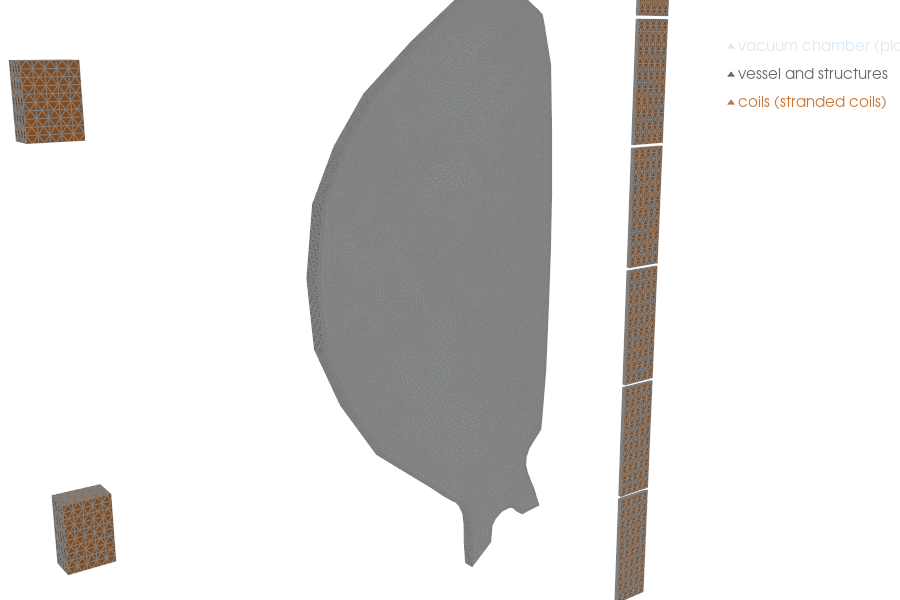

In [4]:
machine = grid.threshold(value=(32.5, 35.5), scalars="TYPE")         # all but the air
pl = pv.Plotter(window_size=(900, 600))
colors = {33: "#dbe9f6", 34: "dimgray", 35: "#c87533"}
for tid, color in colors.items():
    part = machine.threshold(value=(tid, tid), scalars="TYPE")
    if part.n_cells:
        pl.add_mesh(part, color=color, show_edges=True, edge_color="gray", line_width=0.3,
                    label={33: "vacuum chamber (plasma region)", 34: "vessel and structures",
                           35: "coils (stranded coils)"}[tid])
pl.add_legend(bcolor="white", size=(0.32, 0.15))
pl.camera_position = [(16, 4, -14), (6, 0, -0.1), (0, 1, 0)]
pl.show()

The picture shows the 2 degree slice of the machine, seen from outside: thin, but a true 3D mesh. The coil cells
already have TYPE 35 in the file; the macro sets it again on the `COILS` cells, with their element coordinate
system, in the next section.

## Voltage-driven coils

Each CS module and PF coil becomes a `STRANDED_COIL` (TYPE 35): a winding of N turns with a current $i$, uniform
over its cross-section, along the direction `T` of the real constants. Its circuit equation links the terminal
voltage `VOLT`, the resistive drop and the induced voltage `EMF` (the time derivative of the flux linked with the
turns):

$$\text{VOLT} = R\,i + \text{EMF}.$$

Points to note for a 3D sector (real constants of each coil):

* `T = (0, 1, 0)` is the **toroidal** direction in the cylindrical element coordinate system 1 (y axis), which the
  coil cells must use (`COORDINATE_SYSTEM = 1`); the vacuum chamber keeps the global system (the algorithm writes
  global components in its `Js`);
* `volume` is the volume of the **whole** coil and `symmetry = 180` (360 / 2 degrees): the model holds 1/180 of each
  coil, and the circuit equation is that of the whole coil (R and N of the whole coil, the EMF of the sector times
  180);
* all the nodes of a coil share one `VOLT` and one `EMF`: a CP id per coil in `CP_0` (1-6, 11-16), and the couplings
  set with `add_dof_couplings` (the model data has none).

The source voltage of each coil is the one that keeps its equilibrium current in steady state, `VOLT = R i`, with
`i = S Js / N` from the current density of the coil in the equilibrium output (its `Jt` holds the same values: the
table shows both). For the four control coils this includes the correction currents of the position control.

In [5]:
coil_names = ["CS3U", "CS2U", "CS1U", "CS1L", "CS2L", "CS3L"] + [f"PFC_{n}" for n in range(1, 7)]
coil_ids = dict(zip(coil_names, list(range(11, 17)) + list(range(1, 7))))   # CP id = real constants row

selection.select(mesh, "COILS", 1, location="elem")
selection.set_value_on_selection(mesh, "TYPE", 35, location="elem")
selection.set_value_on_selection(mesh, "COORDINATE_SYSTEM", 1, location="elem")
solver.model.set_coordinate_system(1, YAxisCylindricalCoordinateSystem())
selection.select(mesh, "VACUUM_CHAMBER", 1, location="elem")
selection.set_value_on_selection(mesh, "COORDINATE_SYSTEM", 0, location="elem")

meshes.remove_array(mesh, "CP_0")
meshes.add_array(mesh, "CP_0", dtype=vtk.VTK_INT)
solver.model.add_dof_couplings({cid: ["VOLT", "EMF"] for cid in coil_ids.values()})
eq_js, eq_jt = meshes.array_values(equilibrium, "Js", "elem"), meshes.array_values(equilibrium, "Jt", "elem")
coils = {}
print(f"{'coil':>6} {'N':>5} {'R [Ohm]':>8} {'i [kA]':>8} {'i from Jt':>9} {'VOLT [V]':>9}")
for name, cid in coil_ids.items():
    selection.select(mesh, name, 1, location="elem")
    selection.nsle(mesh)
    selection.set_value_on_selection(mesh, "CP_0", cid)
    master = int(selection.selected_ids(mesh, "node")[0])          # the lowest node id: the master of the coupling
    turns, resistance, section_area = (solver.model.real_constant(cid, key)
                                       for key in ("turns", "resistance", "cross_section"))
    on = meshes.array_values(equilibrium, name, "elem") == 1
    current = section_area * eq_js[on, 2].mean() / turns            # A per turn
    selection.select(mesh, "ID", master)
    selection.set_value_on_selection(mesh, "_VOLT", resistance * current)
    coils[name] = {"master": master, "turns": turns, "resistance": resistance, "i0": current}
    print(f"{name:>6} {turns:5.0f} {resistance:8.4f} {current / 1e3:8.3f} "
          f"{section_area * eq_jt[on, 2].mean() / turns / 1e3:9.3f} {resistance * current:9.2f}")

  coil     N  R [Ohm]   i [kA] i from Jt  VOLT [V]
  CS3U   553   0.0209   -8.717    -8.717   -182.55
  CS2U   553   0.0209   -7.320    -7.320   -153.30
  CS1U   553   0.0209  -37.620   -37.620   -787.85
  CS1L   553   0.0209  -37.620   -37.620   -787.85
  CS2L   553   0.0209  -18.620   -18.620   -389.95
  CS3L   553   0.0209    9.586     9.586    200.76
 PFC_1   249   0.0163   23.022    23.022    374.79
 PFC_2   116   0.0169  -24.883   -24.883   -420.14
 PFC_3   186   0.0393  -31.277   -31.277  -1228.17
 PFC_4   170   0.0357  -28.149   -28.149  -1004.75
 PFC_5   217   0.0320  -35.992   -35.992  -1151.10
 PFC_6   460   0.0332   36.828    36.828   1221.97


## Cyclic symmetry, boundary conditions and gauge

* **Cyclic symmetry**: every node of the face at 0 degrees is coupled with its image at 2 degrees, for `A` and `V`
  (`periodic_boundaries`, in a second CP array, `CP_1`, since a node of a coil face already has a `CP_0` id). With
  edge elements the coupled values are scalars (circulations along the edges), so no nodal frame rotation is needed.
* **Far boundary**: the tangential $A$ vanishes on the sphere of radius 100 m: the edge DOFs, stored as component 2 of
  `_A` on the midside nodes, are fixed to zero there.
* **Gauge**: the edge discretisation of $A$ has no Coulomb gauge term; a tree-cotree decomposition of the mesh edges
  fixes $A = 0$ on the edges of a spanning tree (`tree_gauge`), built consistently with the periodic pairs.
* **Potential of the structures**: $V$ is defined up to a constant in each solid conductor not connected to a
  source: it is fixed to zero on one node of the vessel (node 16170).

In [6]:
from pytec3d import tree_gauge
eps, sector, divisions = 0.1, 2.0, 4
cylindrical = YAxisCylindricalCoordinateSystem()
meshes.remove_array(mesh, "CP_1")
meshes.add_array(mesh, "CP_1", dtype=vtk.VTK_INT)
selection.select_pos(mesh, 1, (-eps, eps), coordinate_system=cylindrical)
pairs = solver.model.periodic_boundaries(cylindrical, dy=sector, array_name="CP_1", variables=("A", "V"))
print(len(pairs), "periodic node pairs")

selection.select_all(mesh)
selection.select_pos(mesh, 0, (90.0, 110.0), coordinate_system=SphericalCoordinateSystem())
selection.set_value_on_selection(mesh, "_A", 0.0, 2)                 # tangential A = 0 (edge DOFs, midside nodes)
tree_gauge.tree_gauge(mesh, periodic_point_coupling="CP_1")
selection.select(mesh, "ID", 16170)
selection.set_value_on_selection(mesh, "_V", 0.0)

with quietly():
    solver.load_model_into_solver()

51533 periodic node pairs


## Algorithm parameters: 3D coupling and halo

Besides the profile parameters of the 2D evolution:

* `extrusion_angle = 2`, `n_toroidal_divisions = 4`: the sector, to build the toroidal maps between the 2D chamber
  and the 3D stations;
* the **halo**: from `t0_halo` = 0.41 s on, when the plasma is limited, the current-carrying region extends beyond the
  last closed surface $\psi_b$ to

  $$\psi_2 = \psi_b - \Delta_1\,(1 + (t - t_0)\,\Delta_2)\,(\psi_{axis} - \psi_b),$$

  with `halo_delta1` $=\Delta_1 = 0.04$ (a halo 4 % of the core flux wide) and `halo_delta2` $= \Delta_2 = 0$ (constant
  width). The same profile applies over core and halo, with $\bar\psi$ normalized on $\psi_2$; along the wall wetted
  by the halo, the poloidal current that crosses the wall between two nodes follows from the change of $F(\psi)$
  between them, and is injected as `AMPS` (nodal current of the potential $V$ of the vessel).

In [7]:
algorithm.input_parameters.update(R0=6.2, alpha_mp=1.0001, alpha_np=0.83197, AF0=5.3 * 6.2,
                                  tolerance_value=1e-4, max_picard_iterations=70,
                                  extrusion_angle=sector, n_toroidal_divisions=divisions,
                                  halo_delta1=0.04, halo_delta2=0.0, t0_halo=0.41)
files = CASE.parent / "files"
t_all = np.loadtxt(files / "time_steps.txt")
ip_all = np.loadtxt(files / "plasma_current.txt")[:len(t_all)]
bp_all = np.loadtxt(files / "beta_p.txt")
pick = np.concatenate(([0], np.arange(150, len(t_all), 150)))       # 30 ms steps
times, ip, bp = t_all[pick], ip_all[pick], bp_all[pick]
print(len(times), "steps up to", times[-1], "s")

22 steps up to 0.63 s


## Post-processing tools

The results are 3D vectors in global components. For pictures and integrals we use:

* `section(grid)`: the cut of the 3D grid by the meridian plane at 0.25 degrees (through the first layer of cells),
  flattened to (R, Z), with the vector cell arrays in **cylindrical** components (R, Z, toroidal) - the toroidal
  sign as in the 2D models, so the plasma current is positive;
* integrals over the first layer of cells (0 - 0.5 degree), times 720 for the whole torus: the toroidal current of a
  region is $\sum J_\varphi\,a$ with the cell area $a = V_{cell} / (R\,\Delta\theta)$;
* the **vertical force** on the structures, $F_Z = \int (\mathbf J\times\mathbf B)_Z\,dV$. The model has no
  toroidal-field coils: its $\mathbf B$ has only the poloidal field (and the small toroidal field of the plasma
  poloidal currents). The force of the poloidal (halo) currents in the vessel comes from the vacuum toroidal field
  $B_\varphi = F_0/R$ (`AF0` = 5.3 T x 6.2 m), which we add here: $F_Z^{halo} = -\int J_R\,B_\varphi\,dV$.

In [8]:
def cylindrical_components(vectors, angle):
    """(R, Z, toroidal) components of global vectors at toroidal angles `angle` (toroidal axis = local z at 0 deg)."""
    c, s = np.cos(angle), np.sin(angle)
    return np.c_[vectors[:, 0] * c - vectors[:, 2] * s, vectors[:, 1], vectors[:, 0] * s + vectors[:, 2] * c]

def section(grid, angle_deg=0.25):
    """The meridian cut at angle_deg, flattened to (R, Z), with Jt, Js, B in cylindrical components (*_cyl)."""
    a = np.radians(angle_deg)
    cut = pv.wrap(grid).slice(normal=(-np.sin(a), 0.0, -np.cos(a)), origin=(0.0, 0.0, 0.0))
    points = cut.points.copy()
    cut.points = np.c_[np.hypot(points[:, 0], points[:, 2]), points[:, 1], np.zeros(len(points))]
    for name in ("Jt", "Js", "B"):
        cut.cell_data[name + "_cyl"] = cylindrical_components(cut.cell_data[name], a)
    return cut.cast_to_unstructured_grid()

dtheta = sector / divisions                            # angle of a cell layer [deg]
layer = theta < np.radians(dtheta)                     # first layer of cells
area = grid.cell_data["cell_volume"] / (radius * np.radians(dtheta))
volume = grid.cell_data["cell_volume"]
types = grid.cell_data["TYPE"]
structure = layer & (types == 34)
b_phi_vacuum = algorithm.input_parameters["AF0"] / radius

def integrals():
    """Toroidal currents of the plasma region, structures and coils, and vertical forces on the structures (torus)."""
    jt = cylindrical_components(meshes.array_values(mesh, "Jt", "elem"), theta)
    js = cylindrical_components(meshes.array_values(mesh, "Js", "elem"), theta)
    j_global, b_global = meshes.array_values(mesh, "Jt", "elem"), meshes.array_values(mesh, "B", "elem")
    f_model = np.cross(j_global, b_global)[:, 1] * volume
    return {"I_plasma": (js[:, 2] * area)[layer & (types == 33)].sum(),
            "I_vessel": (jt[:, 2] * area)[structure].sum(),
            "Fz_model": f_model[structure].sum() * 360 / dtheta,
            "Fz_halo": (-jt[:, 0] * b_phi_vacuum * volume)[structure].sum() * 360 / dtheta,
            "jpol_max": np.hypot(jt[:, 0], jt[:, 1])[structure].max()}

## The time loop

As in 2D: a static step 0 (the coils at their source voltages, `VOLT = R i`, give back the equilibrium currents),
then transient backward-Euler steps of 30 ms, with an evolution solve (Picard iterations of 3D solves) per step. After
each step we record the status, the coil currents $i = (\text{VOLT} - \text{EMF})/R$ at the master node of each
coil, the integrals above, the halo injection of the 2D chamber (`AMPS` of `algorithm.vacuum_chamber_mesh`), the
flux and current of the chamber, and the meridian section.

In [9]:
solver.time_step["theta"] = 1.0
chamber = algorithm.vacuum_chamber_mesh
records, started = [], time.perf_counter()
for k, t in enumerate(times):
    solver.time_step["transient_effects"] = k > 0
    solver.time_step["time"] = t if k > 0 else 1e-10
    algorithm.input_parameters.update(plasma_current=ip[k], beta_p=bp[k])
    step_start = time.perf_counter()
    with quietly():
        algorithm.evolution_solve()
    st = dict(algorithm.status)
    psi_c = meshes.array_values(chamber, "PSI", "node")
    if k == 0:
        st.update(magnetic_axis=tuple(meshes.points(chamber)[np.argmax(psi_c)]), separatrix_configuration="initial")
    volt, emf = meshes.array_values(mesh, "VOLT", "node"), meshes.array_values(mesh, "EMF", "node")
    amps = meshes.array_values(chamber, "AMPS", "node")
    records.append({"t": t, "status": st, "seconds": time.perf_counter() - step_start,
                    "coil_i": {n: (volt[c["master"]] - emf[c["master"]]) / c["resistance"] for n, c in coils.items()},
                    "psi": psi_c.copy(), "psie": meshes.array_values(chamber, "PSIe", "elem").copy(),
                    "js": meshes.array_values(chamber, "Js", "elem").copy(),
                    "amps": amps.copy(), "halo": amps[amps > 0].sum() * 360 / sector,
                    "section": section(mesh), **integrals()})
    r = records[-1]
    print(f"step {k:2d} t = {t:.2f} s {st['picard_iteration']:2d} it. axis ({st['magnetic_axis'][0]:.2f}, "
          f"{st['magnetic_axis'][1]:+.2f}) {st['separatrix_configuration']:8s} vessel {r['I_vessel'] / 1e6:+.3f} MA"
          f"  halo {r['halo'] / 1e3:5.1f} kA  [{time.perf_counter() - started:4.0f} s]")

step  0 t = 0.00 s  1 it. axis (6.49, +0.53) initial  vessel +0.000 MA  halo   0.0 kA  [  16 s]
step  1 t = 0.03 s 12 it. axis (6.49, +0.53) X-point  vessel -0.097 MA  halo   0.0 kA  [  87 s]
step  2 t = 0.06 s 13 it. axis (6.45, +0.58) X-point  vessel -0.091 MA  halo   0.0 kA  [ 161 s]
step  3 t = 0.09 s 14 it. axis (6.41, +0.54) X-point  vessel -0.089 MA  halo   0.0 kA  [ 240 s]
step  4 t = 0.12 s 15 it. axis (6.41, +0.54) X-point  vessel -0.097 MA  halo   0.0 kA  [ 323 s]
step  5 t = 0.15 s 15 it. axis (6.41, +0.54) X-point  vessel -0.108 MA  halo   0.0 kA  [ 407 s]
step  6 t = 0.18 s 16 it. axis (6.38, +0.59) X-point  vessel -0.116 MA  halo   0.0 kA  [ 496 s]
step  7 t = 0.21 s 17 it. axis (6.38, +0.59) X-point  vessel -0.122 MA  halo   0.0 kA  [ 589 s]
step  8 t = 0.24 s 19 it. axis (6.33, +0.58) X-point  vessel -0.127 MA  halo   0.0 kA  [ 695 s]
step  9 t = 0.27 s 20 it. axis (6.30, +0.64) X-point  vessel -0.131 MA  halo   0.0 kA  [ 807 s]
step 10 t = 0.30 s 19 it. axis (6.30, +0

## Results

### Overview

The axis trajectory, the toroidal current of the structures, the change of the coil currents (ampere-turns), the
vertical force on the structures (eddy and halo terms), the Picard iterations per step, and the halo current
entering the wall (whole torus) with the largest poloidal current density in the structures. Dotted line: first
limited step; shaded: halo active.

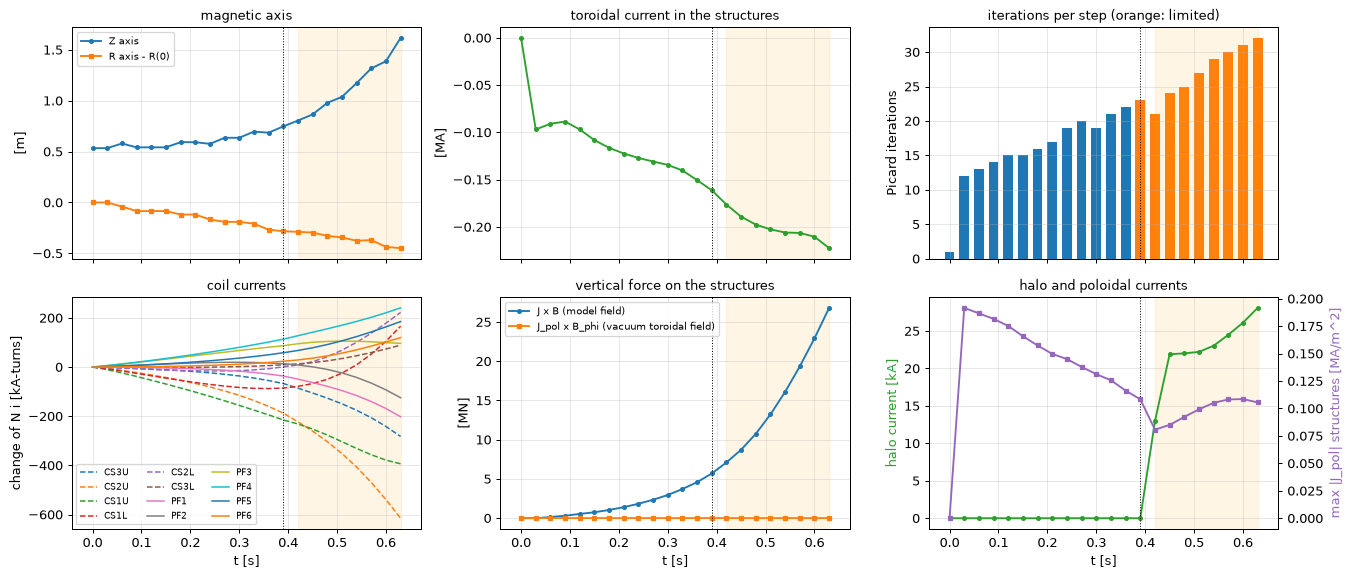

In [10]:
t = np.array([r["t"] for r in records])
axis = np.array([r["status"]["magnetic_axis"][:2] for r in records])
config = [r["status"]["separatrix_configuration"] for r in records]
limited = np.array([c == "limiter" for c in config])
halo_on = np.array([np.abs(r["amps"]).sum() > 0 for r in records])
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True)
ax = axes[0, 0]
ax.plot(t, axis[:, 1], "o-", ms=3, label="Z axis"); ax.plot(t, axis[:, 0] - axis[0, 0], "s-", ms=3, label="R axis - R(0)")
ax.set_ylabel("[m]"); ax.legend(fontsize=8); ax.set_title("magnetic axis", fontsize=10)
ax = axes[0, 1]
ax.plot(t, [r["I_vessel"] / 1e6 for r in records], "o-", ms=3, color="C2")
ax.set_ylabel("[MA]"); ax.set_title("toroidal current in the structures", fontsize=10)
ax = axes[1, 0]
for name in coil_names:
    di = np.array([r["coil_i"][name] - coils[name]["i0"] for r in records]) * coils[name]["turns"] / 1e3
    ax.plot(t, di, lw=1.2, label=name.replace("PFC_", "PF"), ls="-" if name.startswith("PF") else "--")
ax.set_ylabel("change of N i [kA-turns]"); ax.set_title("coil currents", fontsize=10); ax.legend(fontsize=7, ncol=3)
ax = axes[1, 1]
ax.plot(t, [r["Fz_model"] / 1e6 for r in records], "o-", ms=3, label="J x B (model field)")
ax.plot(t, [r["Fz_halo"] / 1e6 for r in records], "s-", ms=3, label="J_pol x B_phi (vacuum toroidal field)")
ax.set_ylabel("[MN]"); ax.set_title("vertical force on the structures", fontsize=10); ax.legend(fontsize=8)
ax = axes[0, 2]
ax.bar(t, [r["status"]["picard_iteration"] for r in records], width=0.02, color=np.where(limited, "C1", "C0"))
ax.set_ylabel("Picard iterations"); ax.set_title("iterations per step (orange: limited)", fontsize=10)
ax = axes[1, 2]
ax.plot(t, [r["halo"] / 1e3 for r in records], "o-", ms=3, color="C2"); ax.set_ylabel("halo current [kA]", color="C2")
ax2 = ax.twinx(); ax2.plot(t, [r["jpol_max"] / 1e6 for r in records], "s-", ms=3, color="C4")
ax2.set_ylabel("max |J_pol| structures [MA/m^2]", color="C4"); ax.set_title("halo and poloidal currents", fontsize=10)
for ax in axes.flat:
    ax.grid(alpha=0.3)
    if limited.any():
        ax.axvline(t[np.argmax(limited)], color="k", ls=":", lw=0.8)
    if halo_on.any():
        ax.axvspan(t[np.argmax(halo_on)], t[-1], color="orange", alpha=0.1)
for ax in axes[1]:
    ax.set_xlabel("t [s]")
plt.tight_layout(); plt.show()

How to read it (and how it compares with the 2D tutorial):

* **Motion.** The same vertical drift, a little slower: the plasma becomes limited at 0.39 s instead of 0.36 s and the
  axis ends at Z = 1.6 m instead of 1.8 m. The structures have the same resistivity, but the coils now react, the
  structures can carry poloidal currents, and the plasma sees the toroidal average of the 3D flux.
* **Vessel current and forces.** The toroidal current induced in the structures grows to about 0.22 MA. Its
  interaction with the poloidal field gives a vertical force on the structures that grows with the displacement, to
  about 27 MN at the end: the order of magnitude of the design loads of the ITER vessel for VDEs.
* **Coils.** With constant source voltages and a tiny resistance, each coil keeps (almost) the flux it links: as the
  plasma moves, its currents change by hundreds of kA-turns, up to 0.6 MA-turns in CS2U (about 15 % of its current).
  The upper CS modules (CS3U, CS2U), which see the plasma come closer, lose current; the coils it moves away from
  gain current. In the 2D tutorial the coil currents were frozen: here they react, through their circuit
  equations, and their response feeds back on the plasma motion. A real machine adds the power supplies and the
  vertical-stability controller, which change the voltages.
* **Poloidal currents in the structures.** Even before the halo the structures carry poloidal currents of about
  0.1 MA/m$^2$. They are induced by the change of the *toroidal* flux of the plasma: its poloidal currents (the
  paramagnetic $F(\psi) > F_0$ of the equilibrium) decrease with $\beta_p$. They peak (0.2 MA/m$^2$) right after
  the fast drop of $\beta_p$ at $t = 0$, and decay with the time constant of the vessel. A 2D model, with only
  toroidal currents, cannot have them.
* **Halo.** From 0.42 s the halo is active and its poloidal current is injected into the wall: some 13 - 28 kA for
  the whole torus, a small fraction of $I_p$. With `halo_delta1 = 0.04` the halo is thin, and the profile
  $(1 - \bar\psi^{\alpha_m})^{\alpha_n}$ normalized on $\psi_2$ is close to zero there, so little current flows in
  it. The halo force ($J_{pol}\times B_\varphi$ with the 5.3 T vacuum field) is negligible here.
  Wider halos (larger `halo_delta1`, growth with `halo_delta2`) or broader edge profiles give the halo fractions of
  tens of per cent seen in VDEs, and forces comparable with the eddy ones.
* **Cost.** Each Picard iteration is a 3D solve with the factorized matrix plus the projections and averages
  between the 2D chamber and the 3D stations: about 5 - 6 s here, against 0.15 s in 2D.

### Core, halo and wall currents

Snapshots of the meridian section: the plasma core (inside $\psi_b$, coloured by $J_\varphi$) and the halo
(between $\psi_b$ and $\psi_2$, green), the toroidal current density in the structures, and the halo injection
points on the wall (`AMPS`: red where the current enters the wall, blue where it leaves, marker area proportional to
the current).

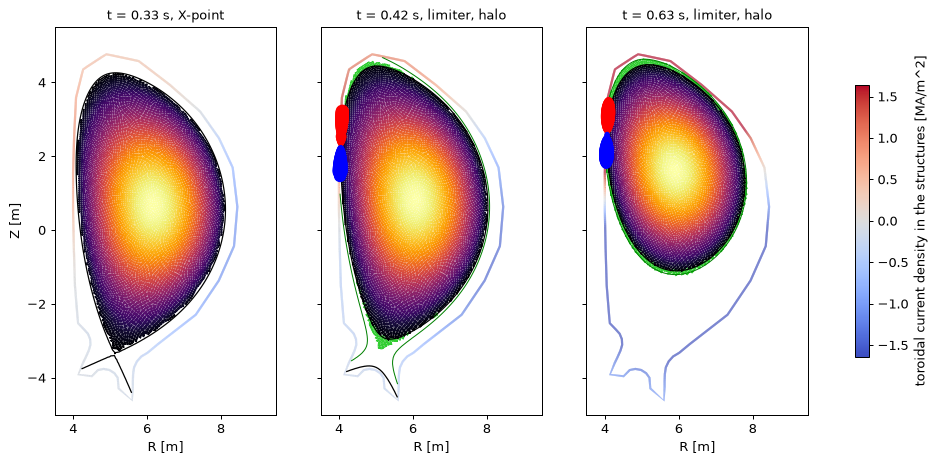

In [11]:
chamber_tri = triangulation(chamber)
chamber_points = meshes.points(chamber)[:, :2]
shown = [11, 14, len(records) - 1]
fig, axes = plt.subplots(1, len(shown), figsize=(13.5, 5.6), sharey=True)
jmax = max(np.abs(records[k]["section"].cell_data["Jt_cyl"][records[k]["section"].cell_data["TYPE"] == 34, 2]).max()
           for k in shown) / 1e6
for ax, k in zip(axes, shown):
    r, st = records[k], records[k]["status"]
    sec = r["section"]
    walls = sec.cell_data["TYPE"] == 34
    pc = fill(ax, sec, walls, sec.cell_data["Jt_cyl"][:, 2] / 1e6, cmap="coolwarm", edgecolor="none")
    pc.set_clim(-jmax / 2, jmax / 2)
    carrying = r["js"][:, 2] != 0
    core = carrying & (r["psie"] >= st["psi_min"])
    halo = carrying & ~core
    fill(ax, chamber, core, r["js"][:, 2] / 1e6, cmap="inferno", edgecolor="none")
    if halo.any():
        fill(ax, chamber, halo, facecolor="limegreen", edgecolor="none")
    ax.tricontour(chamber_tri, r["psi"], levels=[st["psi_min"]], colors="k", linewidths=1.0, linestyles="solid")
    if st["psi_2_min"] < st["psi_min"]:
        ax.tricontour(chamber_tri, r["psi"], levels=[st["psi_2_min"]], colors="green", linewidths=0.8,
                      linestyles="solid")
    hit = r["amps"] != 0
    if hit.any():
        size = 120 * np.abs(r["amps"][hit]) / np.abs(r["amps"]).max()
        ax.scatter(*chamber_points[hit].T, s=size, c=np.where(r["amps"][hit] > 0, "red", "blue"), zorder=5)
    frame(ax, r=(3.5, 9.5), z=(-5.0, 5.5))
    ax.set_title(f"t = {r['t']:.2f} s, {st['separatrix_configuration']}" + (", halo" if halo.any() else ""),
                 fontsize=10)
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.colorbar(pc, ax=axes, shrink=0.7, label="toroidal current density in the structures [MA/m^2]")
plt.show()

### The halo current through the wall

A zoom on the contact region at the last step, with the **poloidal** current density in the structures (the R and Z
components of `Jt`, colour and arrows). The halo current enters the wall above the contact point (red) and leaves it
below (blue), flowing along the vessel shell in between: a current path that only the 3D A-V model, with the
potential $V$, can carry. Here it is small against the poloidal currents induced by the change of toroidal flux: 13 -
28 kA spread over a wall section of about 1.5 m$^2$ (the shell thickness times $2\pi R$) is some 0.02 MA/m$^2$,
against 0.1 MA/m$^2$ of induced current.

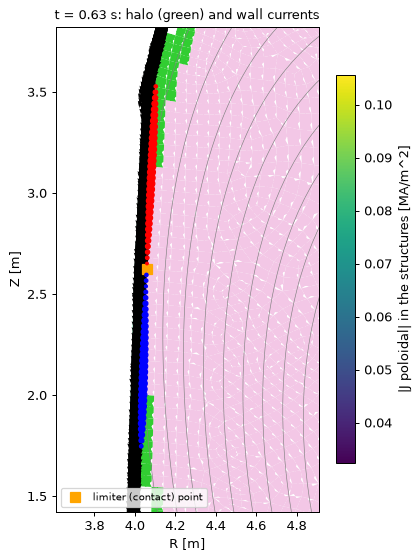

In [12]:
r, st = records[-1], records[-1]["status"]
sec = r["section"]
walls = sec.cell_data["TYPE"] == 34
j_pol = sec.cell_data["Jt_cyl"][:, :2]
centres = sec.cell_centers().points[:, :2]
contact = np.array(st["limiter_point"][:2])
window = walls & (np.abs(centres[:, 0] - contact[0]) < 0.6) & (np.abs(centres[:, 1] - contact[1]) < 1.3)
window[np.flatnonzero(window)[1::2]] = False                     # every second cell: readable arrows
fig, ax = plt.subplots(figsize=(5, 7))
pc = fill(ax, sec, walls, np.linalg.norm(j_pol, axis=1) / 1e6, cmap="viridis", edgecolor="none")
fig.colorbar(pc, ax=ax, shrink=0.8, label="|J poloidal| in the structures [MA/m^2]")
carrying = r["js"][:, 2] != 0
core = carrying & (r["psie"] >= st["psi_min"])
fill(ax, chamber, core, facecolor="#f3c7e6", edgecolor="none")
fill(ax, chamber, carrying & ~core, facecolor="limegreen", edgecolor="none")
ax.tricontour(chamber_tri, r["psi"], levels=np.sort(st["psi_min"] + np.linspace(-0.15, 0.6, 12)
              * (st["psi_magnetic_axis"] - st["psi_min"])), colors="0.5", linewidths=0.5, linestyles="solid")
ax.quiver(*centres[window].T, *j_pol[window].T, color="k", angles="xy", scale_units="xy",
          scale=np.linalg.norm(j_pol[window], axis=1).max() / 0.2, width=0.004, headwidth=4)
hit = r["amps"] != 0
ax.scatter(*chamber_points[hit].T, s=40 * np.abs(r["amps"][hit]) / np.abs(r["amps"]).max() + 4,
           c=np.where(r["amps"][hit] > 0, "red", "blue"), zorder=5)
ax.plot(*contact, "s", color="orange", ms=8, label="limiter (contact) point")
frame(ax, r=(contact[0] - 0.45, contact[0] + 0.85), z=(contact[1] - 1.2, contact[1] + 1.2))
ax.legend(fontsize=8, loc="lower left"); ax.set_title(f"t = {r['t']:.2f} s: halo (green) and wall currents", fontsize=10)
plt.show()

## A 3D view

The last step: the vessel revolved by 240 degrees, coloured by the poloidal current density; the last closed flux
surface (violet) and the halo boundary $\psi_2$ (green, translucent) as surfaces of revolution; the arrows on the 3D sector itself (at 0 - 2
degrees, the cut face on the right) show the direction of the poloidal current density in the structure cells
near the contact point.

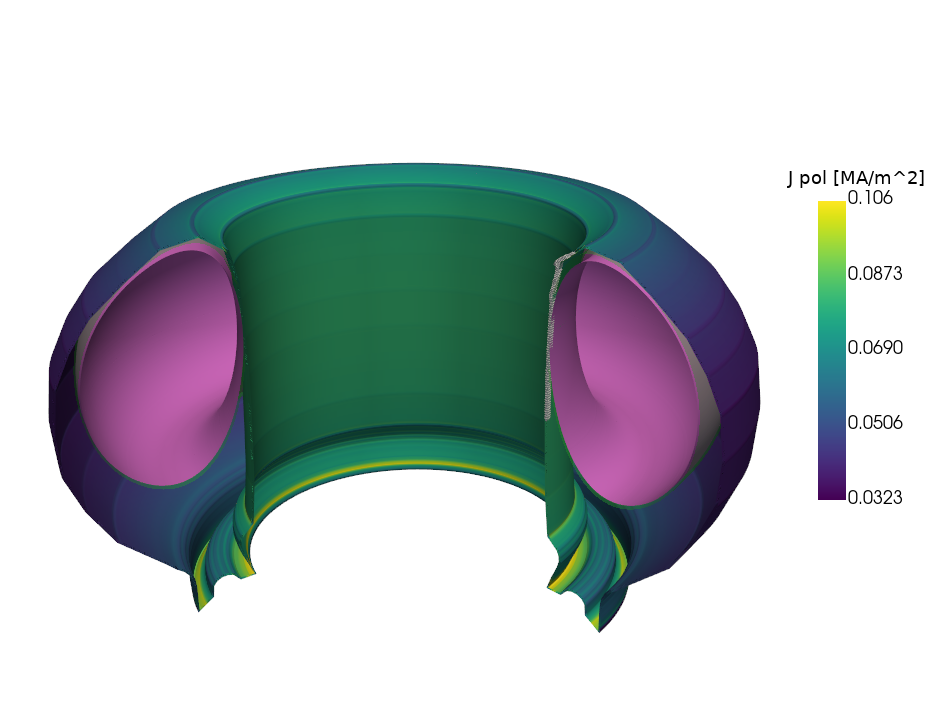

In [13]:
def revolved(surface, angle=240, capping=False):
    outline = surface.extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False,
                                            non_manifold_edges=False)
    return outline.extrude_rotate(resolution=80, angle=angle, rotation_axis=(0, 1, 0), capping=capping)

sec = records[-1]["section"].copy()
sec.cell_data["|J pol| [MA/m^2]"] = np.linalg.norm(sec.cell_data["Jt_cyl"][:, :2], axis=1) / 1e6
wall = sec.extract_cells(np.flatnonzero(sec.cell_data["TYPE"] == 34)).extract_surface(algorithm=None)
wall = wall.cell_data_to_point_data()
plasma_2d = pv.wrap(chamber).copy()
core_cells = np.flatnonzero(core)
halo_cells = np.flatnonzero(carrying & ~core)
pl = pv.Plotter(window_size=(950, 720))
pl.add_mesh(revolved(wall), scalars="|J pol| [MA/m^2]", cmap="viridis", smooth_shading=True,
            scalar_bar_args={"vertical": True, "position_x": 0.86, "position_y": 0.3})
plasma_2d.point_data["PSI"] = records[-1]["psi"]
def flux_surface(level):
    """The flux surface psi = level revolved by 240 degrees (from the contour line of the 2D chamber)."""
    line = plasma_2d.contour([level], scalars="PSI")
    return line.extrude_rotate(resolution=80, angle=240, rotation_axis=(0, 1, 0), capping=False)
pl.add_mesh(flux_surface(st["psi_min"]), color="orchid", smooth_shading=True)
if halo_cells.size:
    pl.add_mesh(flux_surface(st["psi_2_min"]), color="limegreen", opacity=0.35, smooth_shading=True)
structure_cells = grid.extract_cells(np.flatnonzero((types == 34)
                                     & (np.hypot(radius - contact[0], centroid[:, 1] - contact[1]) < 2.0)))
centres_3d = structure_cells.cell_centers()
near = np.flatnonzero((types == 34) & (np.hypot(radius - contact[0], centroid[:, 1] - contact[1]) < 2.0))
j3 = structure_cells.cell_data["Jt"]
phi_hat = np.c_[np.sin(theta[near]), np.zeros(near.size), np.cos(theta[near])]
centres_3d["J_pol"] = j3 - np.sum(j3 * phi_hat, axis=1)[:, None] * phi_hat        # the poloidal part of Jt
pl.add_mesh(centres_3d.glyph(orient="J_pol", scale=False, factor=0.25), color="white")
pl.camera_position = [(19, 13, 24), (2, 1.5, 0), (0, 1, 0)]
pl.show()
with quietly():
    solver.close()

## Notes and going further

* **The full test** (`examples/ITER_3D_evol_coils_edge/macro.py`) runs the same model with 1 ms steps (637 steps), a long
  run.
* **Halo injection on the stations.** The algorithm computes the halo current of the sector (scaled by
  `extrusion_angle / 360`) and shares it among the five node stations of the wall (every 0.5 degree) with the
  trapezoid weights 1/4, 1/2, 1/4: stations 0 and 2 are one periodic pair, whose loads add up, so the sector receives
  its share once (*Theory - Halo currents*).
* **Other 3D cases**: `ITER_3D_evol` (coils with fixed currents), `ITER_3D_evol_edge` and `ITER_3D_evol_coils_edge`
  (edge elements and the tree-cotree gauge), `ITER_3D_evol_fine*` (finer meshes).
* **Non-axisymmetric structures**: this sector is axisymmetric. A sector with ports or blanket modules meshed in 3D
  carries fully 3D eddy and halo current paths, coupled with the same 2D plasma (*Theory - 3D coupling*).